In [1]:
import pandas as pd
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

data_path = Path("../data/processed")

orders = pd.read_csv(data_path / "orders.csv", parse_dates=["order_date"])
items = pd.read_csv(data_path / "order_items.csv")

print(orders.shape, items.shape)

(100000, 16) (254331, 9)


In [2]:
valid_orders = orders[orders["order_status"] == "Delivered"].copy()

print("Delivered orders:", len(valid_orders))
print("Customers:", valid_orders["customer_id"].nunique())
print("Date range:", valid_orders["order_date"].min(), "to",
      valid_orders["order_date"].max())

Delivered orders: 80679
Customers: 21849
Date range: 2023-01-01 00:00:00 to 2025-12-31 00:00:00


In [3]:
cutoff_date = pd.Timestamp("2025-07-01")
future_end = pd.Timestamp("2026-01-01")

history = valid_orders[valid_orders["order_date"] < cutoff_date]
future = valid_orders[
    (valid_orders["order_date"] >= cutoff_date) &
    (valid_orders["order_date"] < future_end)
]

print("History orders:", len(history))
print("Future orders:", len(future))

History orders: 56714
Future orders: 23965


In [4]:
features = history.groupby("customer_id").agg(
    order_count=("order_id", "nunique"),
    first_order=("order_date", "min"),
    last_order=("order_date", "max")
)

features["recency_days"] = (
    cutoff_date - features["last_order"]
).dt.days

features["customer_age_days"] = (
    cutoff_date - features["first_order"]
).dt.days

features = features[["order_count", "recency_days", "customer_age_days"]]

features.head()

,order_count,recency_days,customer_age_days
customer_id,,,
CUST100000,2,767,854
CUST100001,7,404,793
CUST100002,7,20,44
CUST100004,2,608,644
CUST100005,2,674,693


In [5]:
future_counts = future.groupby("customer_id")["order_id"].nunique()

features["repeat_next_6m"] = (
    features.index.to_series().map(future_counts).fillna(0) >= 1
).astype(int)

print(features["repeat_next_6m"].value_counts())
features.head()

repeat_next_6m
0    13106
1     3873
Name: count, dtype: int64


,order_count,recency_days,customer_age_days,repeat_next_6m
customer_id,,,,
CUST100000,2,767,854,0
CUST100001,7,404,793,0
CUST100002,7,20,44,1
CUST100004,2,608,644,0
CUST100005,2,674,693,0


In [6]:
print("Rows:", len(features))
print("Missing values:", features.isnull().sum().sum())
print("Target distribution:")
print(features["repeat_next_6m"].value_counts(normalize=True).round(3))

Rows: 16979
Missing values: 0
Target distribution:
repeat_next_6m
0    0.772
1    0.228
Name: proportion, dtype: float64


In [7]:
from sklearn.model_selection import train_test_split

X = features.drop(columns="repeat_next_6m")
y = features["repeat_next_6m"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (13583, 3) Test: (3396, 3)


In [8]:
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
print("Model training complete.")

Model training complete.


In [9]:
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, predictions, zero_division=0))
print("Confusion matrix:\n", confusion_matrix(y_test, predictions))

if y_test.nunique() == 2:
    print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 3))

              precision    recall  f1-score   support

           0       0.94      0.76      0.84      2621
           1       0.50      0.83      0.62       775

    accuracy                           0.77      3396
   macro avg       0.72      0.79      0.73      3396
weighted avg       0.84      0.77      0.79      3396

Confusion matrix:
 [[1984  637]
 [ 135  640]]
ROC-AUC: 0.86


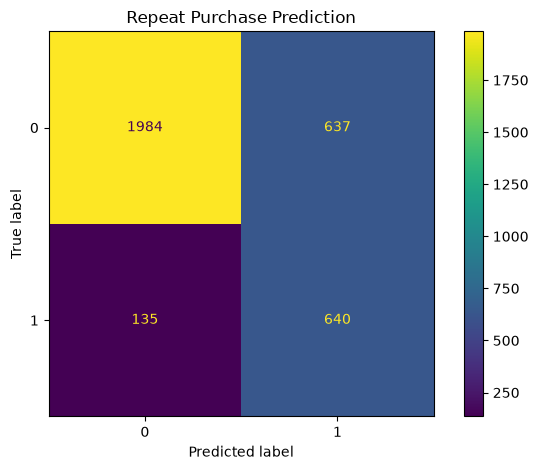

In [10]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions)
plt.title("Repeat Purchase Prediction")
plt.tight_layout()
plt.show()

recency_days         0.597265
customer_age_days    0.345611
order_count          0.057124
dtype: float64


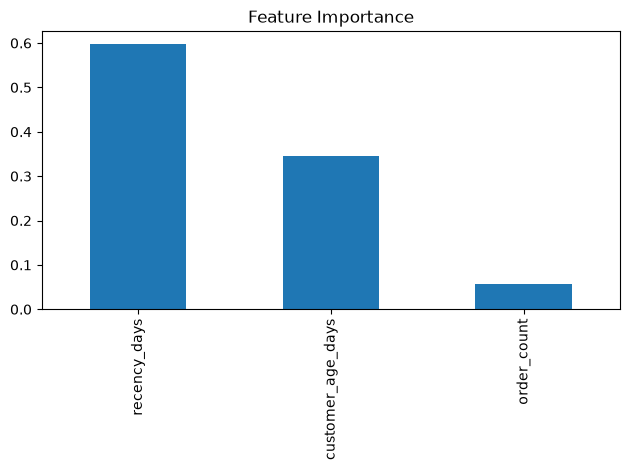

In [11]:
importance = pd.Series(
    model.feature_importances_, index=X.columns
).sort_values(ascending=False)

print(importance)

importance.plot(kind="bar", title="Feature Importance")
plt.tight_layout()
plt.show()

In [12]:
import joblib

model_path = Path("../models")
model_path.mkdir(parents=True, exist_ok=True)

joblib.dump(model, model_path / "repeat_purchase_model.pkl")
joblib.dump(list(X.columns), model_path / "model_features.pkl")

print("Model and feature list saved.")

Model and feature list saved.


In [13]:
import joblib

joblib.dump(model, model_path / "repeat_purchase_model.pkl")
joblib.dump(list(X.columns), model_path / "model_features.pkl")

loaded_model = joblib.load(model_path / "repeat_purchase_model.pkl")

print("Model saved and loaded successfully.")
print("Features:", list(X.columns))
print("Predictions:", loaded_model.predict(X_test.head(5)))

Model saved and loaded successfully.
Features: ['order_count', 'recency_days', 'customer_age_days']
Predictions: [0 0 0 1 0]



## Model Evaluation

The repeat-purchase prediction model was evaluated using classification metrics.

- Accuracy: 77%
- ROC-AUC: 0.86
- Class 1 Precision: 0.50
- Class 1 Recall: 0.83

### Conclusion

The model identifies many customers likely to make repeat purchases.
However, some positive predictions are incorrect, so predictions should
be treated as estimates rather than guarantees.

Further improvements may include feature validation, threshold tuning,
and comparison with a baseline model.
